# Entrenamiento y evaluación en Google Colab

Flujo completo del proyecto: datos → entrenamiento de la ablación → evaluación → figuras → exportación de pesos.

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*.

**Persistencia.** Todo lo que no es temporal se escribe en `MyDrive/clifford_nvs`:

| Ruta en Drive | Contenido |
|---|---|
| `data/` | `.npz` preprocesados (se generan una sola vez) |
| `runs/<modelo>/seed<k>/` | `last.pt`, `best.pt`, `log.json`, `summary.json` |
| `results/` | tablas, figuras y CSV del artículo |
| `release/` | pesos publicables y muestra de demostración |

Cada run guarda `last.pt` cada 500 pasos o cada 10 minutos, lo que ocurra antes, con escritura atómica. Si Colab corta la sesión, se agota la cuota de GPU o se apaga tu PC, no se pierden más de 10 minutos de entrenamiento: basta con volver a ejecutar las celdas 1, 2 y 4. Los runs terminados se saltan y el interrumpido continúa desde su checkpoint con la misma secuencia aleatoria.

In [11]:
# 1. Entorno, Drive y código
import os, subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout or "Sin GPU: revisa el tipo de entorno")

from google.colab import drive
drive.mount("/content/drive")

WORK = "/content/drive/MyDrive/clifford_nvs"      # carpeta persistente (datos, runs, resultados)
CODE_DRIVE = "/content/drive/MyDrive/clifford-nvs"   # código subido a Drive
REPO_URL = ""   # opcional: "https://github.com/<usuario>/clifford-nvs.git" para clonar desde GitHub
REPO = "/content/clifford-nvs"
os.makedirs(WORK, exist_ok=True)

import shutil
if REPO_URL:
    if not os.path.isdir(REPO):
        !git clone -q {REPO_URL} {REPO}
    else:
        !git -C {REPO} pull -q
else:
    # Copia local del código en Drive: ejecutarlo desde el disco de la sesión es más rápido.
    assert os.path.isdir(f"{CODE_DRIVE}/src"), f"No se encontró el código en {CODE_DRIVE}"
    shutil.rmtree(REPO, ignore_errors=True)
    shutil.copytree(CODE_DRIVE, REPO, ignore=shutil.ignore_patterns("__pycache__", "*.pt", "*.npz"))
%cd {REPO}
!pip -q install -r requirements.txt

import sys

# Ejecuta un comando mostrando su salida en vivo y detiene la celda si falla.
# Se usa en lugar de `!` para no depender de la expansión de variables de IPython.
def run(*args):
    cmd = [str(a) for a in args]
    with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1) as proc:
        for line in proc.stdout:
            print(line, end="")
    if proc.returncode:
        raise RuntimeError(f"El comando terminó con código {proc.returncode}: {' '.join(cmd)}")

PY = [sys.executable, "-u", "-m"]   # -u: salida sin búfer para ver el progreso en vivo

Tesla T4, 15360 MiB

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/clifford-nvs


In [12]:
# 2. Datos: srn_cars.zip → .npz de 64×64 en Drive, copiados al disco local de la sesión
import glob, shutil

DRIVE_DATA, DATA = f"{WORK}/data", "/content/data"
needed = [f"cars_{s}_64.npz" for s in ("train", "val", "test")]

if not all(os.path.exists(f"{DRIVE_DATA}/{f}") for f in needed):
    zips = glob.glob("/content/drive/MyDrive/**/srn_cars.zip", recursive=True)
    if zips:
        zip_path = zips[0]
    else:
        import gdown
        listing = gdown.download_folder(id="1PsT3uKwqHHD2bEEHkIXB99AlIjtmrEiR", skip_download=True, quiet=True)
        file_id = next(f.id for f in listing if f.path.endswith("srn_cars.zip"))
        zip_path = "/content/srn_cars.zip"
        gdown.download(id=file_id, output=zip_path, quiet=False)
    run("unzip", "-q", "-n", zip_path, "-d", "/content/srn")
    run(*PY, "src.data", "--srn_root", "/content/srn", "--out", DRIVE_DATA)

# Leer desde el disco local es varias veces más rápido que desde Drive.
os.makedirs(DATA, exist_ok=True)
for f in needed:
    if not os.path.exists(f"{DATA}/{f}"):
        shutil.copy(f"{DRIVE_DATA}/{f}", f"{DATA}/{f}")
print("Datos listos:", sorted(os.listdir(DATA)))

Datos listos: ['cars_test_64.npz', 'cars_train_64.npz', 'cars_val_64.npz']


In [13]:
# 3. Experimentos
CONFIGS = ["configs/A_conv_matrix.yaml", "configs/B_clifford_matrix.yaml", "configs/C_clifford_rotor.yaml"]
SEEDS = [0, 1]
SESSION_HOURS = 3.5        # tiempo de GPU que se dedicará en esta sesión
# CONFIGS.append("configs/D_conv_rotor.yaml")   # diseño factorial completo, si hay tiempo

import sys
sys.path.insert(0, REPO)
from src.utils import load_config
from src.models import build_model, count_params
for c in CONFIGS:
    cfg = load_config(c)
    print(f"{cfg['name']:20s} {count_params(build_model(cfg['model'])) / 1e6:.3f} M parámetros, "
          f"{cfg['train']['steps']} pasos")

A_conv_matrix        3.156 M parámetros, 6000 pasos
B_clifford_matrix    3.148 M parámetros, 6000 pasos
C_clifford_rotor     3.214 M parámetros, 6000 pasos


In [14]:
# 4. Entrenamiento (re-ejecutable: salta lo terminado y reanuda lo interrumpido)
import time
t0 = time.time()
for seed in SEEDS:                      # primero todas las configuraciones con la semilla 0
    for c in CONFIGS:
        left = SESSION_HOURS - (time.time() - t0) / 3600
        if left < 0.05:
            break
        run(*PY, "src.train", "--config", c, "--seed", seed, "--data", DATA, "--work", WORK,
            "--time_budget_h", f"{left:.3f}")
print(f"Tiempo de la sesión: {(time.time() - t0) / 3600:.2f} h")

/content/drive/MyDrive/clifford_nvs/runs/A_conv_matrix/seed0: entrenamiento ya completado
/content/drive/MyDrive/clifford_nvs/runs/B_clifford_matrix/seed0: entrenamiento ya completado
/content/drive/MyDrive/clifford_nvs/runs/C_clifford_rotor/seed0: entrenamiento ya completado
/content/drive/MyDrive/clifford_nvs/runs/A_conv_matrix/seed1: entrenamiento ya completado
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Reanudando /

In [15]:
# 5. Estado de los runs
import pandas as pd
from src.utils import read_json
rows = []
for c in CONFIGS:
    name = load_config(c)["name"]
    for seed in SEEDS:
        d = f"{WORK}/runs/{name}/seed{seed}"
        log = read_json(f"{d}/log.json") if os.path.exists(f"{d}/log.json") else None
        summ = read_json(f"{d}/summary.json") if os.path.exists(f"{d}/summary.json") else None
        rows.append({"run": name, "seed": seed,
                     "estado": "completo" if summ else ("en curso" if log else "pendiente"),
                     "paso": log["train"][-1]["step"] if log and log["train"] else 0,
                     "mejor val PSNR": max((v["psnr"] for v in log["val"]), default=None) if log else None,
                     "horas GPU": summ["gpu_hours"] if summ else None})
pd.DataFrame(rows)

,run,seed,estado,paso,mejor val PSNR,horas GPU
0,A_conv_matrix,0,completo,6000,19.323954,0.677305
1,A_conv_matrix,1,completo,6000,19.341112,0.692513
2,B_clifford_matrix,0,completo,6000,18.832075,1.493285
3,B_clifford_matrix,1,completo,6000,19.018847,1.523993
4,C_clifford_rotor,0,completo,6000,19.128788,1.588832
5,C_clifford_rotor,1,completo,6000,18.883781,1.505785


In [16]:
# 6. Evaluación en prueba (704 objetos × 16 vistas) y tablas LaTeX
RESULTS = f"{WORK}/results"
run(*PY, "src.evaluate", "--configs", *CONFIGS, "--seeds", *SEEDS, "--data", DATA, "--work", WORK, "--out", RESULTS)

Pares de prueba: 11264 (704 objetos)
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0%|          | 0.00/528M [00:00<?, ?B/s]
  2%|▏         | 12.9M/528M [00:00<00:04, 135MB/s]
  6%|▌         | 31.5M/528M [00:00<00:03, 170MB/s]
 10%|▉         | 51.8M/528M [00:00<00:02, 189MB/s]
 13%|█▎        | 70.8M

Figuras escritas en /content/drive/MyDrive/clifford_nvs/results


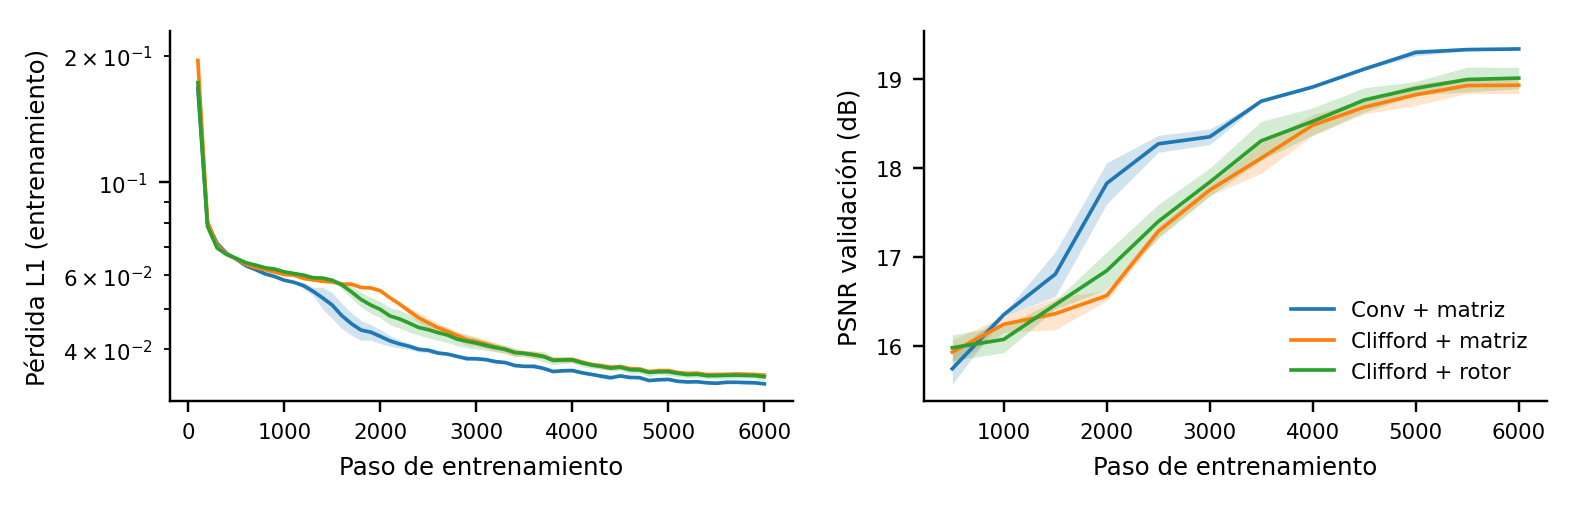

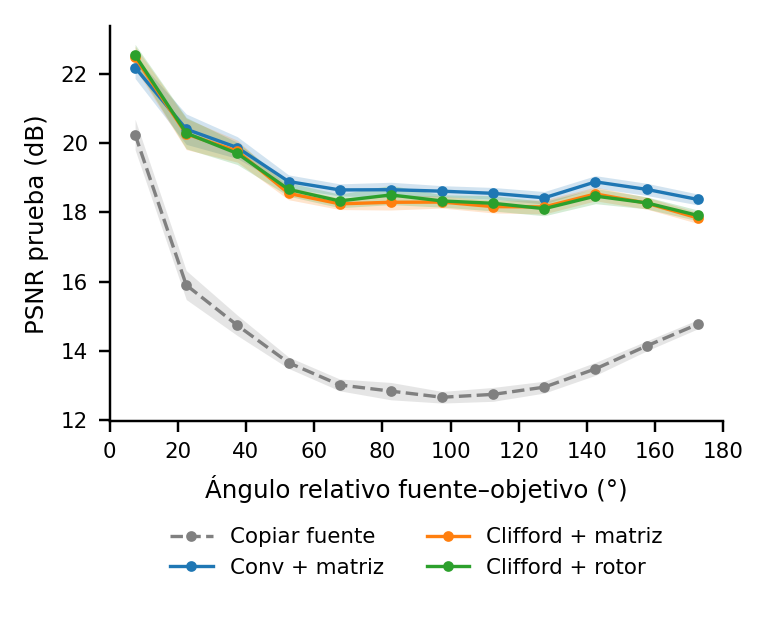

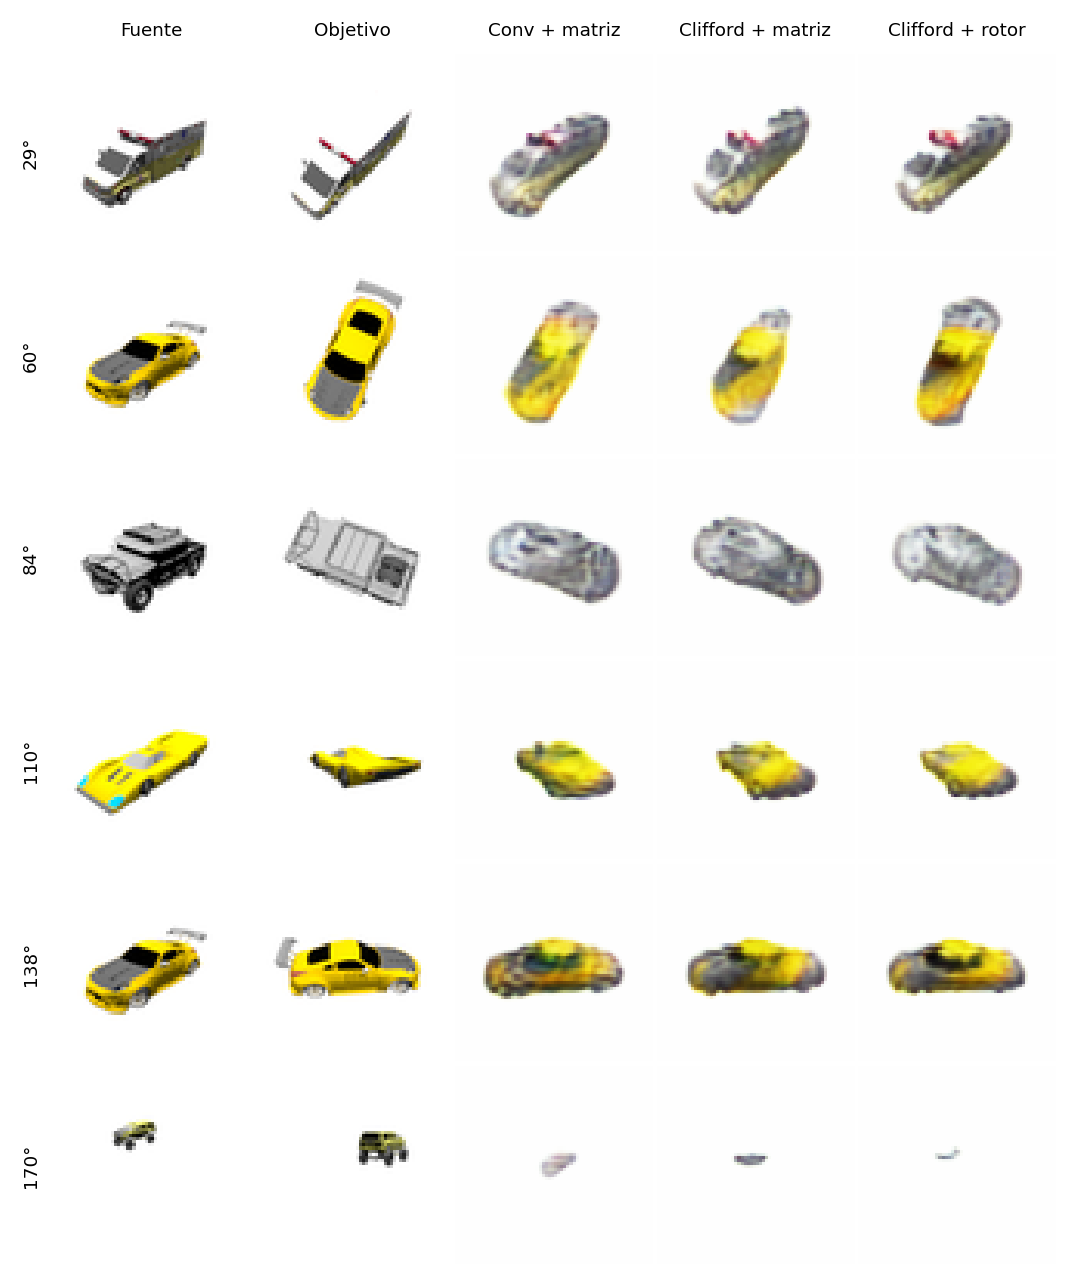

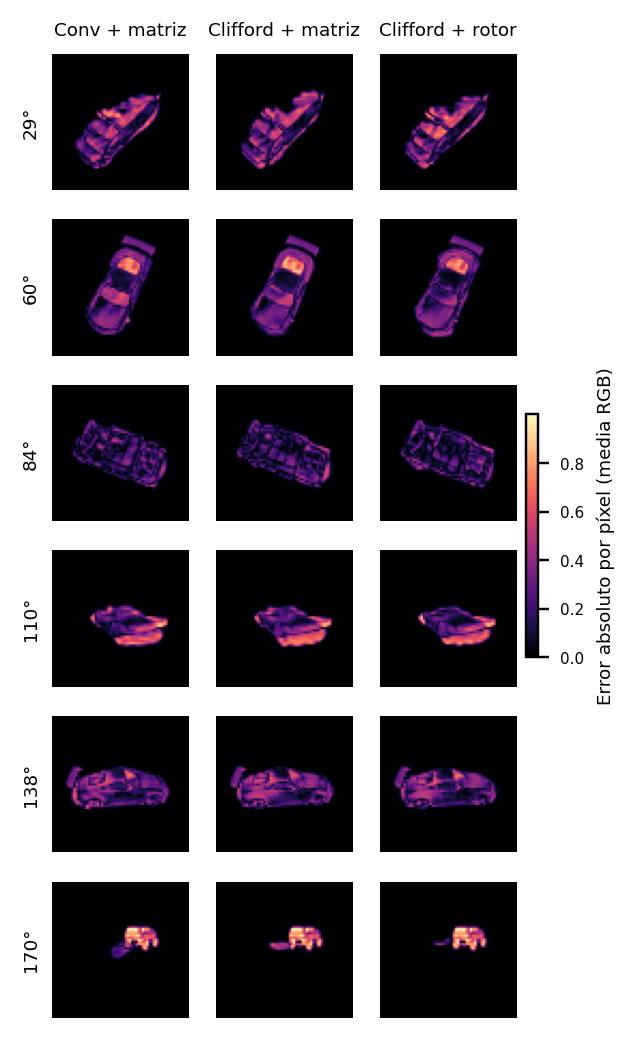

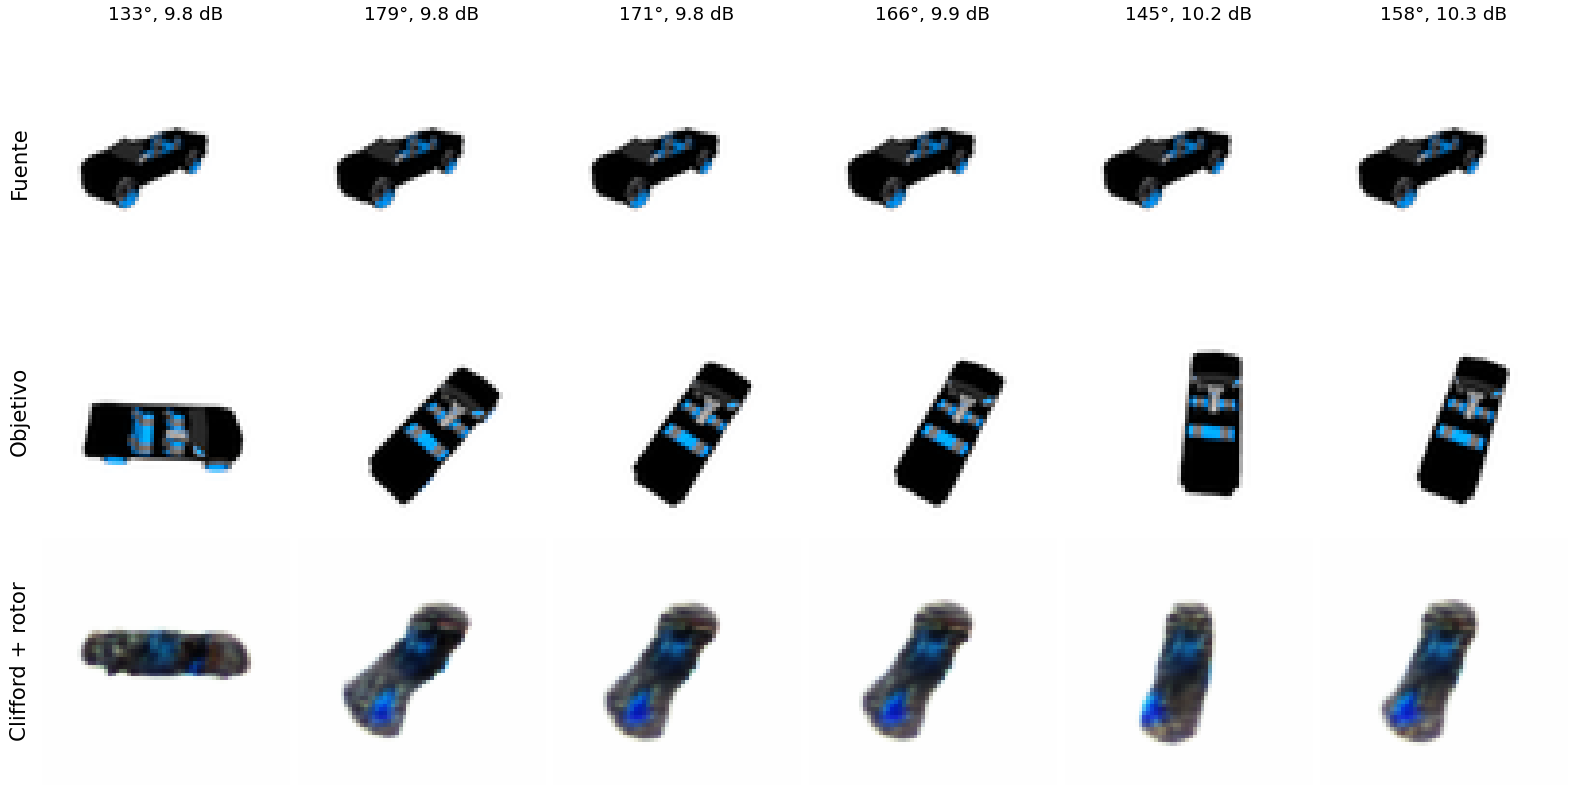

In [17]:
# 7. Figuras y copia de registros
FOCUS = "configs/C_clifford_rotor.yaml"   # modelo del análisis de peores casos
run(*PY, "src.figures", "--configs", *CONFIGS, "--seeds", *SEEDS, "--data", DATA, "--work", WORK,
    "--out", RESULTS, "--focus", FOCUS)

os.makedirs(f"{RESULTS}/logs", exist_ok=True)
for c in CONFIGS:
    name = load_config(c)["name"]
    for seed in SEEDS:
        for f in ("log.json", "summary.json"):
            p = f"{WORK}/runs/{name}/seed{seed}/{f}"
            if os.path.exists(p):
                shutil.copy(p, f"{RESULTS}/logs/{name}_seed{seed}_{f}")

from IPython.display import Image, display
for fig in ("fig_curvas", "fig_psnr_angulo", "fig_cualitativa", "fig_error", "fig_peores_casos"):
    if os.path.exists(f"{RESULTS}/{fig}.png"):
        display(Image(f"{RESULTS}/{fig}.png", width=700))

In [18]:
# 8. Pesos publicables y paquete de resultados para el repositorio
run(*PY, "src.export", "--configs", *CONFIGS, "--seeds", 0, "--data", DATA, "--work", WORK, "--out", f"{WORK}/release")
shutil.make_archive("/content/results", "zip", RESULTS)
print("1) Comparte la carpeta MyDrive/clifford_nvs/release como 'Cualquier persona con el enlace' y")
print("   copia su ID en README.md y en notebooks/02_demo_inferencia.ipynb.")
print("2) Descarga /content/results.zip y descomprímelo en results/ del repositorio antes del commit.")
from google.colab import files
files.download("/content/results.zip")

/content/drive/MyDrive/clifford_nvs/release/A_conv_matrix_seed0.pt  (paso 6000, validación 19.32 dB)
/content/drive/MyDrive/clifford_nvs/release/B_clifford_matrix_seed0.pt  (paso 5500, validación 18.83 dB)
/content/drive/MyDrive/clifford_nvs/release/C_clifford_rotor_seed0.pt  (paso 5500, validación 19.13 dB)
demo_sample.npz: 5 objetos, 1255 vistas
1) Comparte la carpeta MyDrive/clifford_nvs/release como 'Cualquier persona con el enlace' y
   copia su ID en README.md y en notebooks/02_demo_inferencia.ipynb.
2) Descarga /content/results.zip y descomprímelo en results/ del repositorio antes del commit.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>